<div style="padding: 28px 32px;
            font-family: 'Georgia', serif;">

  <p style="margin:0; font-size:13px; letter-spacing:3px; text-transform:uppercase; color:#b0477d;">
     Machine Learning · CA1 
  </p>

  <h1 style="margin:8px 0 4px 0; font-size:32px;">
    Gymnastics Prediction CA1
  </h1>

  <p style="margin:4px 0; font-size:15px;"><b>Student:</b> María Fernanda López Díaz</p>
  <p style="margin:4px 0; font-size:15px;"><b>Student ID:</b> 2026794</p>
  <p style="margin:4px 0; font-size:15px;"><b>Lecturer:</b> Dr. Muhammad Iqbal </p>
  <p style="margin:4px 0; font-size:15px;"><b>GitHub:</b>
    <a href="https://github.com/CCT-Dublin/hdipdata-sept26-ft-stage-1-sem1-data-prep-ca1-mafs794" style="color:#b0477d;">
      github.com/CCT-Dublin/hdipdata-sept26-ft-stage-1-sem1-data-prep-ca1-mafs794t</a></p>
</div>

In [1]:
import pandas as pd 
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [2]:
raw_data = pd.read_csv("data/data_2022_2023.csv")

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">1. Data Preparation</h2>
</div>

In [3]:
raw_data.head()

,LastName,FirstName,Gender,Country,Date,Competition,Round,Location,Apparatus,Rank,D_Score,E_Score,Penalty,Score
0,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",HB,18.0,3.9,8.266,NaN,12.166
1,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",PB,23.0,3.9,6.900,NaN,10.800
2,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",PH,33.0,4.2,6.666,NaN,10.866
3,AAS,Fredrik,m,NOR,23-26 Feb 2023,2023 Cottbus World Cup,qual,"Cottbus, Germany",HB,39.0,4.6,6.700,NaN,11.300
4,AAS,Fredrik,m,NOR,23-26 Feb 2023,2023 Cottbus World Cup,qual,"Cottbus, Germany",PH,44.0,4.4,7.800,NaN,12.200


In [4]:
raw_data.shape

(24434, 14)

The dataset contains 24,434 observations and 14 features. This is the hole dataset, as we are goinf to predict if a gymnast is making in into finals, we are going to base de prediction only with those gymnasts that are in the round qual (short for qualification round or qualifier).

In [5]:
raw_data['Round'].unique()

<StringArray>
['qual', 'AAfinal', 'TeamFinal', 'final', 'TeamQual', 'AAqual']
Length: 6, dtype: str

In [6]:
qual_data = raw_data[raw_data['Round'] == 'qual']

In [7]:
qual_data['Apparatus'].unique()

<StringArray>
['HB', 'PB', 'PH', 'FX', 'SR', 'VT1', 'VT2', 'BB', 'UB', 'hb', 'VT']
Length: 11, dtype: str

VT1 AND VT2 ar abbreviations for VT, we are going to merge it because it means that is the first round and second round for Vault. 'hb' IS HB (Higher Bar) in lower case.

In [8]:
qual_data["Apparatus"] = qual_data["Apparatus"].replace({"VT1": "VT", "VT2": "VT"})

Using only the quad Round we obtain a dataset with 16,058 observations and 14 features. 

In [9]:
qual_data["Apparatus"] = qual_data["Apparatus"].replace({"hb": "HB"})

In [10]:
qual_data.isnull().sum()

LastName           0
FirstName          3
Gender             0
Country            0
Date               0
Competition        0
Round              0
Location           0
Apparatus          0
Rank             699
D_Score            0
E_Score            0
Penalty        12847
Score              0
dtype: int64

We have 3 columns with missing values: "First Name" "Rank" and "Penalty". 
We are going to drop the null values in Rank because without a Rank we cannot make our target variable "top8". Regarding Penalty we have to investigate a little more. 

In [11]:
qual_data['Penalty'].unique()

array([nan, 0.3, 0.1, 0.4, 0.9, 0. , 0.2, 4.3, 0.6, 3. , 4. , 5.3, 0.5,
       8. , 0.7, 3.3, 6.5, 2. , 6. , 1. , 8.1, 0.8, 4.5, 2.1, 6.3, 5. ,
       8.5])

In [12]:
#check if Score column (D_Score + E_Scoreis equal to Score in rows where penalty is null
#this will help us identify if there is a data entry error in the Score column or penalty column
score_check = qual_data[
    qual_data['Penalty'].isnull() &
    np.isclose(qual_data['D_Score'] + qual_data['E_Score'], qual_data['Score'], atol=0.001)
]

In [13]:
score_check.shape

(12840, 14)

We obtain only 9,843 out of 12,847 with null in penalty. As we are not able to identify where the problem is (data entry error or what) we are going to drop the columns where the score doesn't match. 

In [14]:
#drop the columns that are have a null value in penalty and are not in the score_check dataframe
qual_data = qual_data.drop(qual_data[qual_data['Penalty'].isnull() & ~qual_data.index.isin(score_check.index)].index)

In [15]:
#drop rows where Rank is null
qual_data = qual_data.drop(qual_data[qual_data['Rank'].isnull()].index)

In [16]:
#change null values in Penalty column to 0
qual_data['Penalty'] = qual_data['Penalty'].fillna(0)

In [17]:
qual_data.isnull().sum()

LastName       0
FirstName      3
Gender         0
Country        0
Date           0
Competition    0
Round          0
Location       0
Apparatus      0
Rank           0
D_Score        0
E_Score        0
Penalty        0
Score          0
dtype: int64

In [18]:
#create the target variable for the model 
#1 if Rank <= 8, else 0
qual_data['Top_8'] = np.where(qual_data['Rank'] <= 8, 1, 0)

In [19]:
qual_data.head(10)

,LastName,FirstName,Gender,Country,Date,Competition,Round,Location,Apparatus,Rank,D_Score,E_Score,Penalty,Score,Top_8
0,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",HB,18.0,3.9,8.266,0.0,12.166,0
1,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",PB,23.0,3.9,6.900,0.0,10.800,0
2,AAS,Fredrik,m,NOR,24-27 Feb 2022,2022 Cottbus World Cup,qual,"Cottbus, Germany",PH,33.0,4.2,6.666,0.0,10.866,0
3,AAS,Fredrik,m,NOR,23-26 Feb 2023,2023 Cottbus World Cup,qual,"Cottbus, Germany",HB,39.0,4.6,6.700,0.0,11.300,0
4,AAS,Fredrik,m,NOR,23-26 Feb 2023,2023 Cottbus World Cup,qual,"Cottbus, Germany",PH,44.0,4.4,7.800,0.0,12.200,0
5,AAS,Fredrik,m,NOR,1-5 Aug 2023,2023 FISU World University Games,qual,"Chengdu, China",FX,54.0,4.0,8.566,0.0,12.566,0
6,AAS,Fredrik,m,NOR,1-5 Aug 2023,2023 FISU World University Games,qual,"Chengdu, China",HB,44.0,4.6,8.166,0.0,12.766,0
7,AAS,Fredrik,m,NOR,1-5 Aug 2023,2023 FISU World University Games,qual,"Chengdu, China",PB,54.0,4.4,8.066,0.0,12.466,0
8,AAS,Fredrik,m,NOR,1-5 Aug 2023,2023 FISU World University Games,qual,"Chengdu, China",PH,58.0,4.4,7.266,0.0,11.666,0
9,AAS,Fredrik,m,NOR,1-5 Aug 2023,2023 FISU World University Games,qual,"Chengdu, China",SR,73.0,3.5,8.366,0.0,11.866,0


Text(0.5, 1.0, 'Correlation Heatmap of Score, Rank')

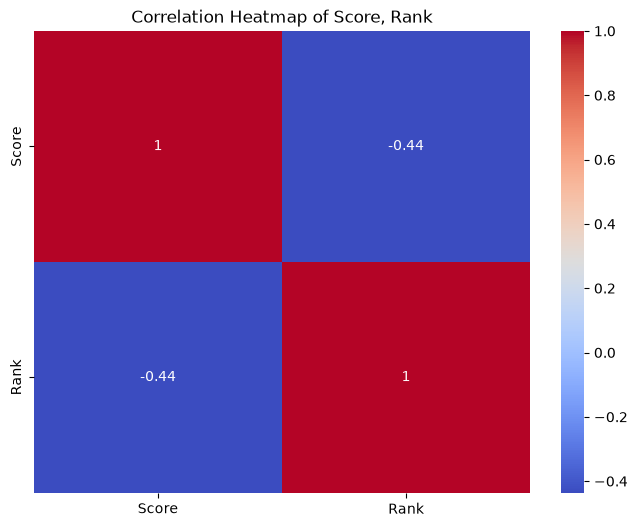

In [20]:
#correlation heatmap of score and rank
plt.figure(figsize=(8, 6))
sns.heatmap(raw_data[['Score', 'Rank']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Score, Rank')

Score and rank are correlated with the target variable Top_8, which is expected since the target variable is derived from the Rank column.
 However, we will drop the Rank and Score columns since they are not needed for the model.

In [21]:
#drop Rank and Score columns since we will not use them in the model
qual_data = qual_data.drop(columns=['Rank', 'Score'])

In [22]:
qual_data.shape

(15353, 13)

In [23]:
#Drop LastName, FirstName, Date, Location, and Round columns 
# since the model can memorise who the gymnast is and where they are competing, which is not useful for prediction
qual_data = qual_data.drop(columns=['LastName', 'FirstName', 'Date', 'Location', 'Round'])

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">2. EDA</h2>
</div>

<Axes: xlabel='Top_8'>

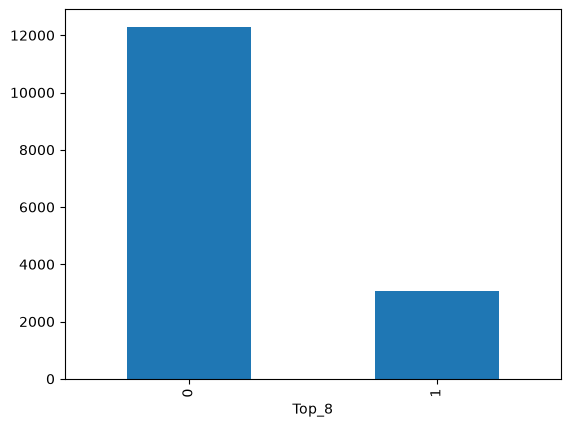

In [24]:
#bar chart showing the class balance of the target variable
qual_data['Top_8'].value_counts().plot(kind='bar')

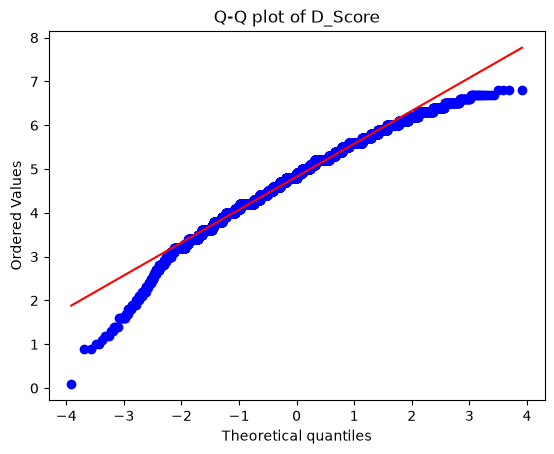

In [25]:
stats.probplot(qual_data['D_Score'], dist="norm", plot=plt)
plt.title("Q-Q plot of D_Score")
plt.show()

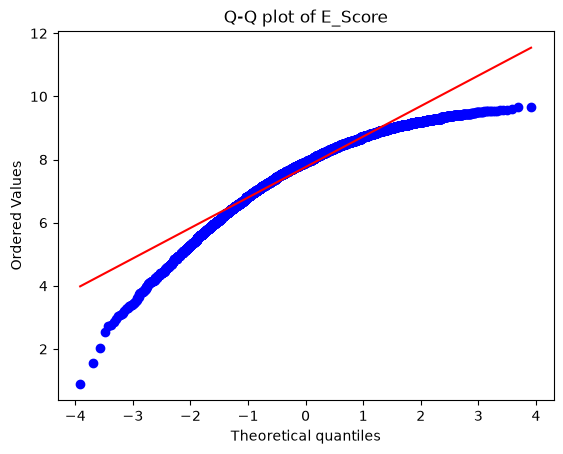

In [26]:
stats.probplot(qual_data['E_Score'], dist="norm", plot=plt)
plt.title("Q-Q plot of E_Score")
plt.show()

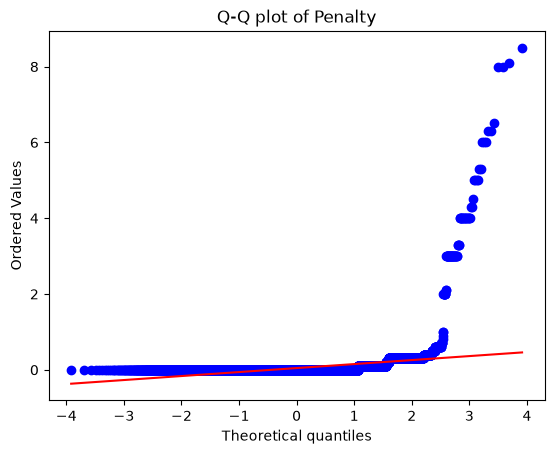

In [27]:
stats.probplot(qual_data['Penalty'], dist="norm", plot=plt)
plt.title("Q-Q plot of Penalty")
plt.show()

Q-Q plots showed that D_Score, E_Score and Penalty are not normally distributed (E_Score is left-skewed and bounded; Penalty is highly right-skewed). 

Text(0.5, 1.0, 'Distribution of D_Score by Apparatus')

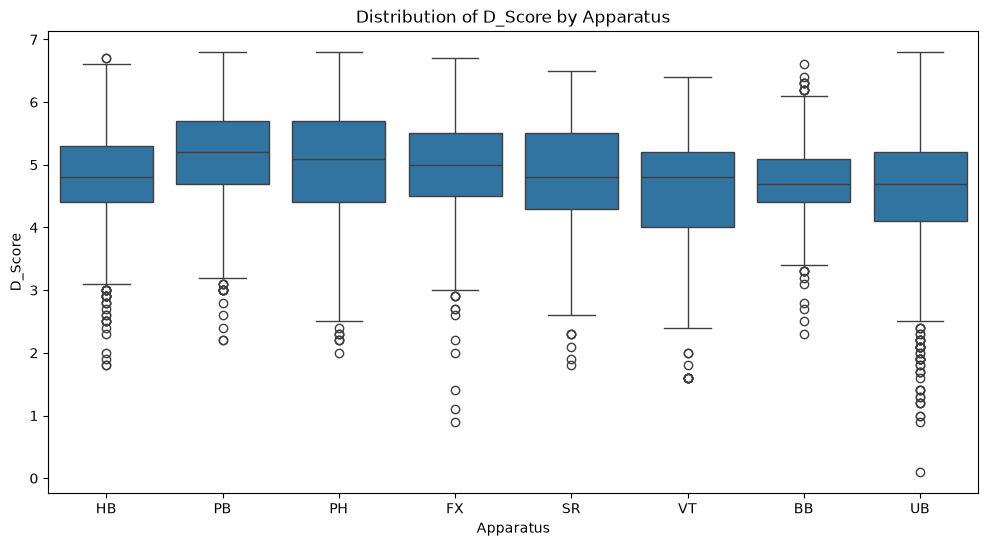

In [28]:
#boxplot showing the distribution of D_Score and E_Score for each apparatus
plt.figure(figsize=(12, 6))
sns.boxplot(x='Apparatus', y='D_Score', data=qual_data)
plt.title('Distribution of D_Score by Apparatus')

Text(0.5, 1.0, 'Distribution of E_Score by Apparatus')

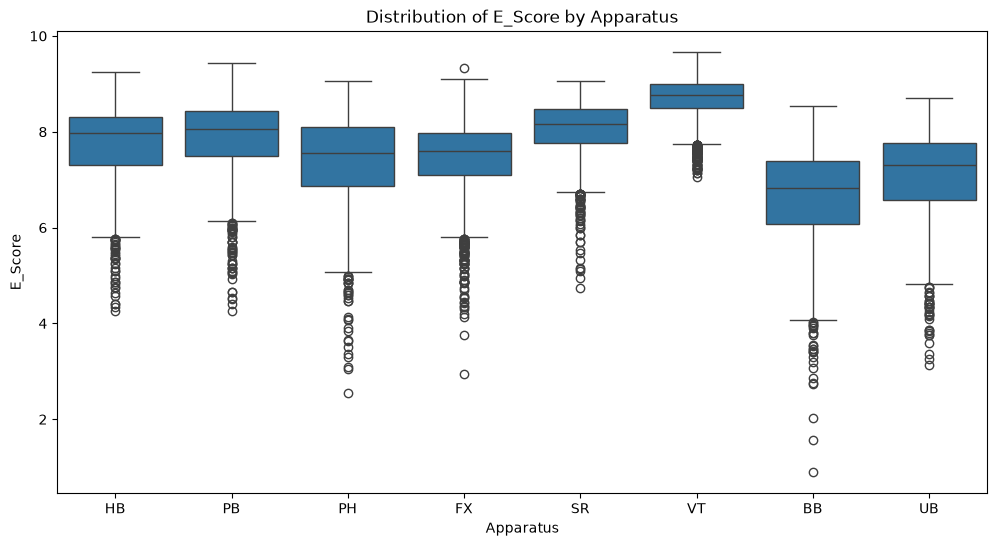

In [29]:
#boxplot showing the distribution of D_Score and E_Score for each apparatus
plt.figure(figsize=(12, 6))
sns.boxplot(x='Apparatus', y='E_Score', data=qual_data)
plt.title('Distribution of E_Score by Apparatus')

Text(0.5, 1.0, 'Correlation Heatmap of D_Score, E_Score, Penalty and Top_8')

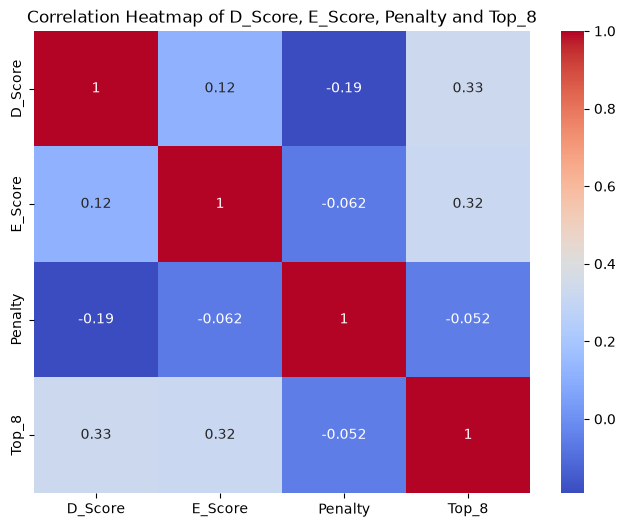

In [30]:
#correlation heatmap of D_Score, E_Score, Penalty and Top_8
plt.figure(figsize=(8, 6))
sns.heatmap(qual_data[['D_Score', 'E_Score', 'Penalty', 'Top_8']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of D_Score, E_Score, Penalty and Top_8')

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">4. Encoding </h2>
</div>

In [31]:
# use one hot encoding for the Apparatus and Gender columns
qual_data = pd.get_dummies(qual_data, columns=['Apparatus', 'Gender', 'Country', 'Competition'], drop_first=True)

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">5. Predicting Models </h2>
</div>

### Separating data into Train and Test

In [32]:
# Define features and target variable
X = qual_data.drop(columns='Top_8')  # Independent Features / columns that will be used to predict 
y = qual_data['Top_8']              # Target variable 

print(X, '\n', y)

       D_Score  E_Score  Penalty  Apparatus_FX  Apparatus_HB  Apparatus_PB  \
0          3.9    8.266      0.0         False          True         False   
1          3.9    6.900      0.0         False         False          True   
2          4.2    6.666      0.0         False         False         False   
3          4.6    6.700      0.0         False          True         False   
4          4.4    7.800      0.0         False         False         False   
...        ...      ...      ...           ...           ...           ...   
24427      5.3    6.850      0.0         False          True         False   
24428      5.3    7.050      0.0         False         False          True   
24430      5.8    7.950      0.1          True         False         False   
24431      5.0    6.250      0.0         False          True         False   
24433      6.0    7.400      0.0         False         False          True   

       Apparatus_PH  Apparatus_SR  Apparatus_UB  Apparatus_VT  

In [33]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

### Training the models with test size of 0.05

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42, stratify=y)

# Create and initialise an object sc by calling a method MinMaxScaler()
scaler = MinMaxScaler()

# Train the model by calling a method fit_transform
X_train = scaler.fit_transform(X_train)

# Store the transformed data into X_test
X_test = scaler.transform(X_test)

#### Applying SMOTE

In [35]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

# Show count of each class in the target variable
class_counts = ys_train.value_counts()
print("Count of each class in 'Top 8':")
print(class_counts)

Count of each class in 'Top 8':
Top_8
0    11679
1    11679
Name: count, dtype: int64


#### Train and evaluate models

In [36]:
# Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(XS_train, ys_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df_005 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df_005)

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.723958   0.802977  0.723958  0.747724
1        Decision Tree  0.886719   0.892194  0.886719  0.888906


In [37]:
# Cross-validation for accuracy on the training set of this split
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df_005 = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df_005)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.842372
1        Decision Tree          0.877203


### Training the models with test size of 0.15

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

# Create and initialise an object sc by calling a method MinMaxScaler()
scaler = MinMaxScaler()

# Train the model by calling a method fit_transform
X_train = scaler.fit_transform(X_train)

# Store the transformed data into X_test
X_test = scaler.transform(X_test)

#### Applying SMOTE

In [39]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

# Show count of each class in the target variable
class_counts = ys_train.value_counts()
print("Count of each class in 'Top 8':")
print(class_counts)

Count of each class in 'Top 8':
Top_8
0    10450
1    10450
Name: count, dtype: int64


#### Train and evaluate models

In [40]:
# Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(XS_train, ys_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df_015 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df_015)

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.702128   0.791701  0.702128  0.728864
1        Decision Tree  0.865393   0.868668  0.865393  0.866870


In [41]:
# Cross-validation for accuracy on the training set of this split
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df_015 = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df_015)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.842222
1        Decision Tree          0.872337


### Training the models with test size of 0.25

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Create and initialise an object sc by calling a method MinMaxScaler()
scaler = MinMaxScaler()

# Train the model by calling a method fit_transform
X_train = scaler.fit_transform(X_train)

# Store the transformed data into X_test
X_test = scaler.transform(X_test)

#### Applying SMOTE

In [43]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

# Show count of each class in the target variable
class_counts = ys_train.value_counts()
print("Count of each class in 'Top 8':")
print(class_counts)

Count of each class in 'Top 8':
Top_8
0    9220
1    9220
Name: count, dtype: int64


#### Train and evaluate models

In [44]:
# Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(XS_train, ys_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df_025 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df_025)

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.682730   0.790578  0.682730  0.712924
1        Decision Tree  0.872363   0.876605  0.872363  0.874198


In [45]:
# Cross-validation for accuracy on the training set of this split
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df_025 = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df_025)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors           0.84445
1        Decision Tree           0.86156


<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">6. GridSearch </h2>
</div>

In [46]:
param_grids = {
    "Decision Tree":{
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9],
        "algorithm": ['auto', 'ball_tree', 'kd_tree', 'brute']
    }
}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42, stratify=y)

# Create and initialise an object sc by calling a method MinMaxScaler()
scaler = MinMaxScaler()

# Train the model by calling a method fit_transform
X_train = scaler.fit_transform(X_train)

# Store the transformed data into X_test
X_test = scaler.transform(X_test)

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])


Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.3s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.3s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.3s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.3s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.4s
[CV] END ......................algorithm=auto, n_neighbors=7; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=7; total time=   0.2s


In [47]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                 Model  Accuracy  Precision    Recall  F1 Score  \
0  k-Nearest Neighbors  0.854167   0.842917  0.854167  0.837153   
1        Decision Tree  0.867188   0.865316  0.867188  0.866182   

                                     Best Parameters  
0       {'algorithm': 'ball_tree', 'n_neighbors': 9}  
1  {'max_depth': 30, 'min_samples_leaf': 1, 'min_...  


In [48]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.3s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.4s
[CV] END ......................algorithm=auto, n_neighbors=3; total time=   0.4s
[CV] END ......................algorithm=auto, n_neighbors=5; total time=   0.4s
[CV] END ......................algorithm=auto, n_neighbors=7; total time=   0.2s
[CV] END ......................algorithm=auto, n_neighbors=7; total time=   0.3s
[CV] END ......................algorithm=auto, n

In [49]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.870970
1        Decision Tree          0.872663
